# Icelandic ASR test evaluation · Person 4 · Ten-model analysis

This notebook evaluates **10 Icelandic ASR systems** using the same **1,884 frozen test clips** and **1,026 speaker/session groups**. It includes the original pretrained baselines, Person 3's recovered Whisper Small step-1000 checkpoint (**test WER 36.06%, CER 10.16%; dev WER 34.51%, CER 9.69%**), Person 5's MFCC + GMM-HMM, Person 2's RNN-T, and three new neural models: CTC encoder, attention-only, and hybrid CTC/attention.

**Run all cells in order on a CPU runtime.** Only saved CSV predictions are evaluated: no model training, GPU or additional test decoding. Internet and `git` are needed to fetch the frozen references and prediction CSVs. The original baselines and normalization are pinned to commit `e9cd03331ef7f2295a5baf197c8c74f1ce41417d`. The recovered Whisper CSV is independently **SHA-256 pinned** to `506f0b277372ebdbba9e08c990e1b691773de6539a2a803b83544d57ac20bf3b` and is rejected if it changes (including when fetched from a moving branch). Two previously verified additional model inputs (GMM-HMM and RNN-T) also have SHA-256 checks. Local-file overrides are available in Section 1.

The evaluation uses **10,000 speaker/session-clustered bootstrap** resamples (seed 2105), **10,000 paired session-level randomization** samples (seed 2106), and Holm adjustment across **90 WER/CER comparisons** (45 model pairs). Results are written to `person4_ten_model_results/`.

**Caveats:** Published Icelandic wav2vec 2.0 and Whisper Small checkpoints may have encountered Samrómur test clips during external training. Original Whisper Small used beam-5 decoding, while recovered fine-tuned Whisper used greedy decoding; their observed difference is not a fully beam-matched fine-tuning estimate.

**Standalone alternative:** `evaluation/person4_evaluate.py`, with dependencies in `evaluation/requirements-person4.txt`.


In [1]:
%pip install -q numpy==2.4.6 pandas==2.2.3 jiwer==4.0.0 matplotlib==3.10.0


## 1. Load frozen references and ten saved prediction files

Fetch the original four baselines and shared normalization from the frozen source commit. Fetch the additional six test prediction files from the team's repository or provide local paths. **The recovered Whisper test input is verified against a fixed SHA-256 checksum** even if its remote branch changes. GMM-HMM and RNN-T inputs have fixed checksums as well; all ten files undergo strict frozen-ID, reference, and session-group validation. No dev predictions are needed for this frozen test comparison.


In [2]:
import csv
import hashlib
import json
import runpy
import subprocess
import sys
from collections import Counter
from pathlib import Path

source_commit = "e9cd03331ef7f2295a5baf197c8c74f1ce41417d"
repo_url = "https://github.com/RanimAlyaseen/icelandic-asr-project3.git"
inputs = Path.cwd() / "person4_inputs"
results_dir = Path.cwd() / "person4_ten_model_results"
# Optional: supply local prediction CSVs instead of fetching them.
# The verified recovered Whisper CSV must match its fixed SHA-256 checksum.
# Example for Colab Drive: Path("/content/drive/MyDrive/person4_evaluation/person3_whisper/test_predictions.csv")
person3_csv_override = None
# For local Colab copies, uncomment these paths if needed:
# person3_csv_override = Path("/content/drive/MyDrive/person4_evaluation/person3_whisper/test_predictions.csv")
gmm_csv_override = None
# gmm_csv_override = Path("/content/mfcc_gmm_hmm_test.csv")
rnnt_csv_override = None
# rnnt_csv_override = Path("/content/rnnt_test.csv")
ctc_csv_override = None
# ctc_csv_override = Path("/content/ctc_scratch_test.csv")
attention_csv_override = None
# attention_csv_override = Path("/content/attention_scratch_test.csv")
hybrid_csv_override = None
# hybrid_csv_override = Path("/content/hybrid_ctc_attention_test.csv")

pretrained = "results/pretrained/predictions"
model_sources = {
    "hubert_ctc_test.csv": "results/hubert_ctc/predictions/hubert_ctc_test.csv",
    "wav2vec2_is_test.csv": f"{pretrained}/wav2vec2_is_test.csv",
    "whisper_small_is_test_beam5.csv": f"{pretrained}/whisper_small_is_test_beam5.csv",
    "whisper_small_test_beam5.csv": f"{pretrained}/whisper_small_test_beam5.csv",
}
inputs.mkdir(exist_ok=True)
git_dir = inputs / "repository"
git_dir.mkdir(exist_ok=True)

def git(*args, **kwargs):
    return subprocess.run(["git", "-C", str(git_dir), *args], check=True, **kwargs)

git("init", "-q")
git("fetch", "-q", "--depth=1", "--no-tags", repo_url, source_commit)

source_files = {
    "evaluation_references.tsv": "output/evaluation_references.tsv",
    "test.jsonl": "output/test.jsonl",
    "prepare.py": "prepare.py",
    "audit.py": "audit.py",
    **model_sources,
}
for filename, repo_path in source_files.items():
    blob = git("show", f"{source_commit}:{repo_path}", capture_output=True).stdout
    (inputs / filename).write_bytes(blob)

model_paths = {name: inputs / name for name in model_sources}
model_files = list(model_paths)

# Recovered checkpoint 1000 predictions are committed on the PR branch.
# Fetch the CSV, not the model weights; evaluation therefore remains CPU-only.
person3_path = inputs / "person3_whisper_test_predictions.csv"
if person3_csv_override is not None:
    person3_path.write_bytes(Path(person3_csv_override).read_bytes())
else:
    source_path = "results/person4_evaluation/person3_whisper/test_predictions.csv"
    for branch in ("person4-evaluation", "main"):
        try:
            git("fetch", "-q", "--depth=1", "--no-tags", repo_url, f"refs/heads/{branch}")
            blob = git("show", f"FETCH_HEAD:{source_path}", capture_output=True).stdout
            person3_path.write_bytes(blob)
            print(f"Fetched Person 3 predictions from {branch}")
            break
        except subprocess.CalledProcessError:
            pass
    else:
        raise FileNotFoundError(
            "Person 3 test_predictions.csv not found on either branch. "
            "Set person3_csv_override to a local copy and rerun."
        )

# Fixed content checksum for the recovered Whisper step-1000 test predictions.
# This check applies to BOTH remote fetches and local overrides.
person3_sha256 = "506f0b277372ebdbba9e08c990e1b691773de6539a2a803b83544d57ac20bf3b"
actual_person3_sha256 = hashlib.sha256(person3_path.read_bytes()).hexdigest()
if actual_person3_sha256 != person3_sha256:
    raise ValueError(
        "Recovered Whisper predictions SHA-256 mismatch: "
        f"expected {person3_sha256}, got {actual_person3_sha256}. "
        "Use the exact frozen results/person4_evaluation/person3_whisper/test_predictions.csv file."
    )
print(f"Verified recovered Whisper SHA-256: {actual_person3_sha256}")

# Fetch a prediction CSV from an existing branch or pull-request ref, or copy a local file.
# SHA-256 pins the previously verified inputs; all others are strictly ID/reference validated.
added_predictions = {
    "mfcc_gmm_hmm_test.csv": {
        "path": "results/mfcc_gmm_hmm/predictions/mfcc_gmm_hmm_test.csv",
        "refs": ("refs/heads/main", "refs/pull/5/head"),
        "override": gmm_csv_override,
        "sha256": "a7657a2d4976b7b60966d395dd787dd2902842bebffbc2ed80214b5e640695e4",
    },
    "rnnt_test.csv": {
        "path": "results/rnnt/predictions/rnnt_test.csv",
        "refs": ("refs/heads/main", "refs/pull/7/head"),
        "override": rnnt_csv_override,
        "sha256": "24eed64f2f19750c802c6069636718fc8113be645ed218cae31acbcde39a3821",
    },
    "ctc_scratch_test.csv": {
        "path": "results/ctc_scratch/predictions/ctc_scratch_test.csv",
        "refs": ("refs/heads/main", "refs/pull/8/head"),
        "override": ctc_csv_override,
        "sha256": None,
    },
    "attention_scratch_test.csv": {
        "path": "results/attention_scratch/predictions/attention_scratch_test.csv",
        "refs": ("refs/heads/main", "refs/pull/8/head"),
        "override": attention_csv_override,
        "sha256": None,
    },
    "hybrid_ctc_attention_test.csv": {
        "path": "results/hybrid_ctc_attention/predictions/hybrid_ctc_attention_test.csv",
        "refs": ("refs/heads/main", "refs/pull/8/head"),
        "override": hybrid_csv_override,
        "sha256": None,
    },
}

for filename, spec in added_predictions.items():
    destination = inputs / filename
    if spec["override"] is not None:
        destination.write_bytes(Path(spec["override"]).read_bytes())
        print(f"Loaded {filename} from local file")
    else:
        for ref in spec["refs"]:
            try:
                git("fetch", "-q", "--depth=1", "--no-tags", repo_url, ref)
                blob = git("show", f"FETCH_HEAD:{spec['path']}", capture_output=True).stdout
                if spec["sha256"] is not None and hashlib.sha256(blob).hexdigest() != spec["sha256"]:
                    print(f"Ignoring changed {filename} at {ref}; checking next ref")
                    continue
                destination.write_bytes(blob)
                print(f"Fetched {filename} from {ref}")
                break
            except subprocess.CalledProcessError:
                continue
        else:
            raise FileNotFoundError(
                f"Could not fetch {filename}. Set its corresponding *_csv_override to a local CSV."
            )
    actual_hash = hashlib.sha256(destination.read_bytes()).hexdigest()
    if spec["sha256"] is not None and actual_hash != spec["sha256"]:
        raise ValueError(f"SHA-256 mismatch for {filename}: {actual_hash}")

# Use the same prepare.py and its local dependency from the pinned commit.
sys.path.insert(0, str(inputs))
try:
    normalize_text = runpy.run_path(str(inputs / "prepare.py"))["normalize_text"]
finally:
    sys.path.pop(0)

def read_rows(path, delimiter=","):
    with path.open(encoding="utf-8-sig", newline="") as file:
        return list(csv.DictReader(file, delimiter=delimiter))

print(f"Source commit: {source_commit}")

Fetched Person 3 predictions from person4-evaluation
Verified recovered Whisper SHA-256: 506f0b277372ebdbba9e08c990e1b691773de6539a2a803b83544d57ac20bf3b
Fetched mfcc_gmm_hmm_test.csv from refs/heads/main
Fetched rnnt_test.csv from refs/heads/main
Fetched ctc_scratch_test.csv from refs/heads/main
Fetched attention_scratch_test.csv from refs/heads/main
Fetched hybrid_ctc_attention_test.csv from refs/heads/main
Source commit: e9cd03331ef7f2295a5baf197c8c74f1ce41417d


## 2. Verify clip IDs, references, and session groups

In [3]:
references = [
    row for row in read_rows(inputs / "evaluation_references.tsv", "\t")
    if row["split"] == "test"
]
official = {row["id"]: row for row in references}
assert len(references) == len(official) == 1884, "Check the frozen test references."

with (inputs / "test.jsonl").open(encoding="utf-8") as file:
    manifest = [json.loads(line) for line in file if line.strip()]
manifest_by_id = {row["id"]: row for row in manifest}
assert len(manifest) == len(manifest_by_id) == len(official)
assert manifest_by_id.keys() == official.keys(), "Test clip IDs differ."
assert all(row["split"] == "test" and row["speaker_session_id"] for row in manifest)
session_by_clip = {
    clip_id: str(row["speaker_session_id"]) for clip_id, row in manifest_by_id.items()
}
assert len(set(session_by_clip.values())) == 1026, "Unexpected session count."

def validate_predictions(rows, frozen, sessions):
    counts = Counter(row["id"] for row in rows)
    return {
        "duplicate IDs": sum(count > 1 for count in counts.values()),
        "missing IDs": len(frozen.keys() - counts.keys()),
        "unexpected IDs": len(counts.keys() - frozen.keys()),
        "wrong split": sum(row["split"] != "test" for row in rows),
        "reference mismatches": sum(
            row["id"] in frozen and (
                row["reference"] != frozen[row["id"]]["text"]
                or row["reference_raw"] != frozen[row["id"]]["text_raw"]
            )
            for row in rows
        ),
        "session mismatches": sum(
            row["id"] in sessions and row["speaker_session_id"] != sessions[row["id"]]
            for row in rows
        ),
        "malformed hypothesis fields": sum(row["hypothesis_raw"] is None for row in rows),
    }

# Verify exact matching, preservation of empty predictions, and duplicate detection.
example_ref = {"0001": {"text": "ég", "text_raw": "Ég."}}
example_sessions = {"0001": "s1"}
example = {
    "id": "0001", "split": "test", "speaker_session_id": "s1",
    "reference": "ég", "reference_raw": "Ég.", "hypothesis_raw": "",
}
assert not any(validate_predictions([example], example_ref, example_sessions).values())
assert validate_predictions([example, example], example_ref, example_sessions)["duplicate IDs"] == 1
bad_example = {**example, "reference": "þú", "speaker_session_id": "s2"}
issues = validate_predictions([bad_example], example_ref, example_sessions)
assert issues["reference mismatches"] == issues["session mismatches"] == 1

rows_by_model = {name: read_rows(path) for name, path in model_paths.items()}
p3_rows = read_rows(person3_path)
if len(p3_rows) != 1884 or any(not all(k in row for k in ("id", "split", "reference", "prediction")) for row in p3_rows):
    raise ValueError("Person 3 file must contain 1,884 rows with id/split/reference/prediction")
p3_converted = []
for row in p3_rows:
    clip_id = row["id"]
    if clip_id not in official:
        raise ValueError(f"Unknown Person 3 clip ID: {clip_id}")
    p3_converted.append({
        "id": clip_id, "split": row["split"],
        "speaker_session_id": session_by_clip[clip_id],
        "reference": row["reference"],
        "reference_raw": official[clip_id]["text_raw"],
        "hypothesis_raw": row["prediction"],
        "hypothesis": normalize_text(row["prediction"]),
    })
rows_by_model["whisper_finetuned_step1000_test.csv"] = p3_converted
model_files.append("whisper_finetuned_step1000_test.csv")

# Additional ASR models use the same baseline CSV schema.
for extra_filename in added_predictions:
    extra_rows = read_rows(inputs / extra_filename)
    if len(extra_rows) != 1884:
        raise ValueError(f"{extra_filename}: expected 1,884 rows, got {len(extra_rows)}")
    rows_by_model[extra_filename] = extra_rows
    model_files.append(extra_filename)
for name, rows in rows_by_model.items():
    issues = validate_predictions(rows, official, session_by_clip)
    failures = {issue: count for issue, count in issues.items() if count}
    if failures:
        raise ValueError(f"{name}: {failures}")
    print(f"PASS {name} | {len(rows):,} rows")
print(f"Verified {len(set(session_by_clip.values())):,} speaker/session groups.")

PASS hubert_ctc_test.csv | 1,884 rows
PASS wav2vec2_is_test.csv | 1,884 rows
PASS whisper_small_is_test_beam5.csv | 1,884 rows
PASS whisper_small_test_beam5.csv | 1,884 rows
PASS whisper_finetuned_step1000_test.csv | 1,884 rows
PASS mfcc_gmm_hmm_test.csv | 1,884 rows
PASS rnnt_test.csv | 1,884 rows
PASS ctc_scratch_test.csv | 1,884 rows
PASS attention_scratch_test.csv | 1,884 rows
PASS hybrid_ctc_attention_test.csv | 1,884 rows
Verified 1,026 speaker/session groups.


## 3. Recalculate WER and CER

Calculate corpus-level scores against the frozen references with shared text normalization. Empty hypotheses count as deletions when the reference has words.


In [4]:
import jiwer

reported = {
    "hubert_ctc_test.csv": (68.46, 23.31),
    "wav2vec2_is_test.csv": (7.76, 1.86),
    "whisper_small_is_test_beam5.csv": (21.75, 5.60),
    "whisper_small_test_beam5.csv": (86.82, 36.35),
    "whisper_finetuned_step1000_test.csv": (36.06, 10.16),
    "mfcc_gmm_hmm_test.csv": (101.47, 87.74),
    "rnnt_test.csv": (68.95, 30.54),
    "ctc_scratch_test.csv": (74.50, 22.88),
    "hybrid_ctc_attention_test.csv": (55.57, 17.77),
    # Attention-only's reported 153.8% WER is rounded to one decimal.
    # Its actual WER and CER are recalculated (153.82%, 92.79%).
}

for filename, rows in rows_by_model.items():
    expected = reported.get(filename)
    refs = [normalize_text(official[row["id"]]["text"]) for row in rows]
    preds = [normalize_text(row["hypothesis_raw"]) for row in rows]

    wer = round(100 * jiwer.wer(refs, preds), 2)
    cer = round(100 * jiwer.cer(refs, preds), 2)
    if expected is not None and (wer, cer) != expected:
        raise ValueError(f"{filename}: recalculated {(wer, cer)} vs reported {expected}")
    status = "MATCH" if expected is not None else "SCORE"

    print(f"{status:5}  {filename:34} WER {wer:6.2f}%  CER {cer:6.2f}%")

MATCH  hubert_ctc_test.csv                WER  68.46%  CER  23.31%
MATCH  wav2vec2_is_test.csv               WER   7.76%  CER   1.86%
MATCH  whisper_small_is_test_beam5.csv    WER  21.75%  CER   5.60%
MATCH  whisper_small_test_beam5.csv       WER  86.82%  CER  36.35%
MATCH  whisper_finetuned_step1000_test.csv WER  36.06%  CER  10.16%
MATCH  mfcc_gmm_hmm_test.csv              WER 101.47%  CER  87.74%
MATCH  rnnt_test.csv                      WER  68.95%  CER  30.54%
MATCH  ctc_scratch_test.csv               WER  74.50%  CER  22.88%
SCORE  attention_scratch_test.csv         WER 153.82%  CER  92.79%
MATCH  hybrid_ctc_attention_test.csv      WER  55.57%  CER  17.77%


## 4. Calculate 95% confidence intervals

Resample whole speaker/session groups 10,000 times with replacement using seed 2105. Each draw uses the same groups for all models. Recompute corpus rates from the sum of errors divided by the sum of reference units. The interval endpoints are the 2.5th and 97.5th percentiles.


In [5]:
import numpy as np

sessions = sorted(set(session_by_clip.values()))
session_index = {session: i for i, session in enumerate(sessions)}
normalized_refs = {
    clip_id: normalize_text(row["text"]) for clip_id, row in official.items()
}

# First two columns are reference word and character counts.
# Each model then gets two columns for word and character errors.
session_totals = np.zeros((len(sessions), 2 + 2 * len(model_files)), dtype=np.int64)

for clip_id, reference in normalized_refs.items():
    i = session_index[session_by_clip[clip_id]]
    session_totals[i, :2] += [len(reference.split()), len(reference)]

for model_index, filename in enumerate(model_files):
    column = 2 + 2 * model_index
    for row in rows_by_model[filename]:
        clip_id = row["id"]
        i = session_index[session_by_clip[clip_id]]
        reference = normalized_refs[clip_id]
        prediction = normalize_text(row["hypothesis_raw"])

        words = jiwer.process_words(reference, prediction)
        chars = jiwer.process_characters(reference, prediction)
        session_totals[i, column:column + 2] += [
            words.substitutions + words.deletions + words.insertions,
            chars.substitutions + chars.deletions + chars.insertions,
        ]

seed = 2105
n_resamples = 10_000
rng = np.random.default_rng(seed)
bootstrap_totals = np.empty((n_resamples, session_totals.shape[1]), dtype=np.int64)

for start in range(0, n_resamples, 250):
    stop = min(start + 250, n_resamples)
    drawn = rng.integers(0, len(sessions), size=(stop - start, len(sessions)))
    bootstrap_totals[start:stop] = session_totals[drawn].sum(axis=1)

observed_totals = session_totals.sum(axis=0)
ci_rows = []

for model_index, filename in enumerate(model_files):
    for offset, metric in enumerate(("WER", "CER")):
        column = 2 + 2 * model_index + offset
        point = 100 * observed_totals[column] / observed_totals[offset]
        bootstrap_rates = 100 * bootstrap_totals[:, column] / bootstrap_totals[:, offset]
        low, high = np.percentile(bootstrap_rates, [2.5, 97.5])

        if filename in reported:
            assert round(point, 2) == reported[filename][offset]
        ci_rows.append({
            "model_file": filename,
            "metric": metric,
            "score_percent": point,
            "ci_low_percent": low,
            "ci_high_percent": high,
        })
        print(f"{filename:34} {metric} {point:6.2f}%  [{low:.2f}%, {high:.2f}%]")

hubert_ctc_test.csv                WER  68.46%  [67.33%, 69.56%]
hubert_ctc_test.csv                CER  23.31%  [22.60%, 24.04%]
wav2vec2_is_test.csv               WER   7.76%  [7.15%, 8.37%]
wav2vec2_is_test.csv               CER   1.86%  [1.69%, 2.04%]
whisper_small_is_test_beam5.csv    WER  21.75%  [20.79%, 22.74%]
whisper_small_is_test_beam5.csv    CER   5.60%  [5.30%, 5.90%]
whisper_small_test_beam5.csv       WER  86.82%  [83.17%, 91.06%]
whisper_small_test_beam5.csv       CER  36.35%  [33.60%, 39.45%]
whisper_finetuned_step1000_test.csv WER  36.06%  [34.78%, 37.32%]
whisper_finetuned_step1000_test.csv CER  10.16%  [9.73%, 10.61%]
mfcc_gmm_hmm_test.csv              WER 101.47%  [101.13%, 101.83%]
mfcc_gmm_hmm_test.csv              CER  87.74%  [87.53%, 87.95%]
rnnt_test.csv                      WER  68.95%  [67.36%, 70.51%]
rnnt_test.csv                      CER  30.54%  [29.66%, 31.42%]
ctc_scratch_test.csv               WER  74.50%  [73.24%, 75.77%]
ctc_scratch_test.csv        

## 5. Compare models in pairs

Differences are model A minus model B in percentage points. The paired percentile intervals reuse the same bootstrap draws and are unadjusted. For p-values, the two-sided paired randomization test swaps model labels by session under an exchangeability assumption. Use 10,000 random draws (seed 2106), a plus-one correction, and Holm adjustment across the displayed tests. These intervals describe test-set sampling variation.


In [6]:
from itertools import combinations

comparisons = []
for a, b in combinations(range(len(model_files)), 2):
    for offset, metric in enumerate(("WER", "CER")):
        comparisons.append((a, b, offset, metric))

# Positive differences mean model A has the higher error rate.
group_differences = np.column_stack([
    session_totals[:, 2 + 2 * a + offset]
    - session_totals[:, 2 + 2 * b + offset]
    for a, b, offset, metric in comparisons
])
observed_differences = group_differences.sum(axis=0)

permutation_seed = 2106
n_permutations = 10_000
rng = np.random.default_rng(permutation_seed)
extreme_counts = np.zeros(len(comparisons), dtype=np.int64)

for start in range(0, n_permutations, 250):
    batch_size = min(250, n_permutations - start)
    signs = 2 * rng.integers(0, 2, size=(batch_size, len(sessions))) - 1
    permuted = signs @ group_differences
    extreme_counts += (
        np.abs(permuted) >= np.abs(observed_differences)
    ).sum(axis=0)

p_values = (extreme_counts + 1) / (n_permutations + 1)

# Holm adjustment across all WER and CER tests in this run.
order = np.argsort(p_values)
holm_p = np.empty_like(p_values)
holm_p[order] = np.minimum(
    1, np.maximum.accumulate(p_values[order] * np.arange(len(order), 0, -1))
)

paired_rows = []
for i, (a, b, offset, metric) in enumerate(comparisons):
    a_column = 2 + 2 * a + offset
    b_column = 2 + 2 * b + offset
    difference = 100 * observed_differences[i] / observed_totals[offset]
    bootstrap_differences = 100 * (
        bootstrap_totals[:, a_column] - bootstrap_totals[:, b_column]
    ) / bootstrap_totals[:, offset]
    low, high = np.percentile(bootstrap_differences, [2.5, 97.5])

    paired_rows.append({
        "model_a": model_files[a],
        "model_b": model_files[b],
        "metric": metric,
        "difference_pp": difference,
        "ci_low_pp": low,
        "ci_high_pp": high,
        "p_value": p_values[i],
        "p_holm": holm_p[i],
    })

    print(
        f"{Path(model_files[a]).stem} vs {Path(model_files[b]).stem} | "
        f"{metric}: {difference:+.2f} pp [{low:+.2f}, {high:+.2f}] | "
        f"p={p_values[i]:.5f}, Holm p={holm_p[i]:.5f}"
    )

hubert_ctc_test vs wav2vec2_is_test | WER: +60.70 pp [+59.60, +61.81] | p=0.00010, Holm p=0.00900
hubert_ctc_test vs wav2vec2_is_test | CER: +21.45 pp [+20.77, +22.16] | p=0.00010, Holm p=0.00900
hubert_ctc_test vs whisper_small_is_test_beam5 | WER: +46.71 pp [+45.58, +47.83] | p=0.00010, Holm p=0.00900
hubert_ctc_test vs whisper_small_is_test_beam5 | CER: +17.71 pp [+17.04, +18.40] | p=0.00010, Holm p=0.00900
hubert_ctc_test vs whisper_small_test_beam5 | WER: -18.36 pp [-22.69, -14.74] | p=0.00010, Holm p=0.00900
hubert_ctc_test vs whisper_small_test_beam5 | CER: -13.04 pp [-16.18, -10.24] | p=0.00010, Holm p=0.00900
hubert_ctc_test vs whisper_finetuned_step1000_test | WER: +32.40 pp [+31.19, +33.59] | p=0.00010, Holm p=0.00900
hubert_ctc_test vs whisper_finetuned_step1000_test | CER: +13.14 pp [+12.47, +13.84] | p=0.00010, Holm p=0.00900
hubert_ctc_test vs mfcc_gmm_hmm_test | WER: -33.01 pp [-34.20, -31.84] | p=0.00010, Holm p=0.00900
hubert_ctc_test vs mfcc_gmm_hmm_test | CER: -64.4

## 6. Summarize recognition errors

An exact word-boundary example preserves the character sequence after removing spaces. It is already represented in the WER alignment counts. Displayed examples are the first occurrence of each category per model in file order.


In [7]:
from itertools import groupby

error_types = {
    "substitute": "substitution",
    "delete": "deletion",
    "insert": "insertion",
}

error_summary = []
error_examples = []

for filename in model_files:
    totals = Counter()
    examples = {}

    for row in rows_by_model[filename]:
        clip_id = row["id"]
        reference = normalized_refs[clip_id]
        prediction = normalize_text(row["hypothesis_raw"])
        aligned = jiwer.process_words(reference, prediction)

        totals["substitutions"] += aligned.substitutions
        totals["deletions"] += aligned.deletions
        totals["insertions"] += aligned.insertions

        ref_words = aligned.references[0]
        pred_words = aligned.hypotheses[0]
        chunks = aligned.alignments[0]

        def record_example(category, ref_tokens, pred_tokens):
            examples.setdefault(category, {
                "model_file": filename,
                "clip_id": clip_id,
                "category": category,
                "reference_span": " ".join(ref_tokens),
                "prediction_span": " ".join(pred_tokens),
                "reference": reference,
                "prediction": prediction,
            })

        for chunk in chunks:
            if chunk.type in error_types:
                record_example(
                    error_types[chunk.type],
                    ref_words[chunk.ref_start_idx:chunk.ref_end_idx],
                    pred_words[chunk.hyp_start_idx:chunk.hyp_end_idx],
                )

        for is_equal, block in groupby(chunks, key=lambda chunk: chunk.type == "equal"):
            if is_equal:
                continue
            edits = list(block)
            ref_span = ref_words[edits[0].ref_start_idx:edits[-1].ref_end_idx]
            pred_span = pred_words[edits[0].hyp_start_idx:edits[-1].hyp_end_idx]

            if (ref_span and pred_span
                    and len(ref_span) != len(pred_span)
                    and "".join(ref_span) == "".join(pred_span)):
                totals["exact_word_boundary_cases"] += 1
                record_example("word boundary", ref_span, pred_span)

    error_summary.append({
        "model_file": filename,
        **{key: totals[key] for key in (
            "substitutions", "deletions", "insertions", "exact_word_boundary_cases"
        )},
    })
    error_examples.extend(examples.values())

    print(f"\n{filename}")
    print(
        f"  Substitutions: {totals['substitutions']:,} | "
        f"Deletions: {totals['deletions']:,} | "
        f"Insertions: {totals['insertions']:,} | "
        f"Exact word-boundary cases: {totals['exact_word_boundary_cases']:,}"
    )
    for category, example in examples.items():
        ref = example["reference_span"] or "∅"
        pred = example["prediction_span"] or "∅"
        print(f"  {example['clip_id']} | {category}: {ref!r} → {pred!r}")


hubert_ctc_test.csv
  Substitutions: 7,727 | Deletions: 2,847 | Insertions: 257 | Exact word-boundary cases: 76
  0064716 | substitution: 'er' → 'erég'
  0064716 | deletion: 'ég' → '∅'
  0064716 | word boundary: 'er ég' → 'erég'
  0016230 | insertion: '∅' → 'velur'

wav2vec2_is_test.csv
  Substitutions: 1,022 | Deletions: 94 | Insertions: 111 | Exact word-boundary cases: 65
  0020846 | substitution: 'summu' → 'sömu'
  0030689 | insertion: '∅' → 'anton í'
  0030689 | word boundary: 'koparpeningar' → 'kopar peningar'
  0007688 | deletion: 'mynd' → '∅'

whisper_small_is_test_beam5.csv
  Substitutions: 2,747 | Deletions: 249 | Insertions: 445 | Exact word-boundary cases: 133
  0011280 | substitution: 'og' → 'á'
  0016230 | insertion: '∅' → 'of'
  0000347 | deletion: 'í' → '∅'
  0220186 | word boundary: 'nýja búningnum' → 'nýjabúningnum'

whisper_small_test_beam5.csv
  Substitutions: 10,068 | Deletions: 650 | Insertions: 3,018 | Exact word-boundary cases: 18
  0064716 | substitution: 'vegn

## 7. Export results and draw the comparison chart

In [8]:
import pandas as pd

results_dir.mkdir(parents=True, exist_ok=True)

tables = {
    "model_scores_and_confidence_intervals.csv": ci_rows,
    "paired_comparisons.csv": paired_rows,
    "error_counts.csv": error_summary,
    "error_examples.csv": error_examples,
}

for filename, rows in tables.items():
    pd.DataFrame(rows).to_csv(results_dir / filename, index=False)
    print(f"Saved {filename} ({len(rows)} rows)")

# Generate the primary fine-tuning comparison from the same computed,
# speaker/session-clustered paired statistics (never hard-code results).
original_model = "whisper_small_test_beam5.csv"
finetuned_model = "whisper_finetuned_step1000_test.csv"
if finetuned_model in rows_by_model:
    score_lookup = {
        (row["model_file"], row["metric"]): row["score_percent"]
        for row in ci_rows
    }
    comparison_rows = []
    for metric in ("WER", "CER"):
        matches = [
            row for row in paired_rows
            if row["model_a"] == original_model
            and row["model_b"] == finetuned_model
            and row["metric"] == metric
        ]
        if len(matches) != 1:
            raise RuntimeError(f"Expected one original-vs-finetuned {metric} comparison")
        paired = matches[0]
        comparison_rows.append({
            "metric": metric,
            "original_percent": round(score_lookup[(original_model, metric)], 2),
            "finetuned_percent": round(score_lookup[(finetuned_model, metric)], 2),
            "improvement_pp": round(paired["difference_pp"], 2),
            "ci_low_pp": round(paired["ci_low_pp"], 2),
            "ci_high_pp": round(paired["ci_high_pp"], 2),
            "p_value": paired["p_value"],
        })
    comparison_path = results_dir / "whisper_finetuning_comparison.csv"
    pd.DataFrame(comparison_rows).to_csv(comparison_path, index=False)
    print(f"Saved {comparison_path} ({len(comparison_rows)} rows)")

methods = {
    "source_commit": source_commit,
    "split": "test",
    "test_clips": len(official),
    "models": model_files,
    "speaker_session_groups": len(sessions),
    "normalization": "prepare.normalize_text from the source commit",
    "confidence_intervals": {
        "method": "95% percentile bootstrap resampling whole speaker/session groups",
        "seed": seed,
        "resamples": n_resamples,
    },
    "paired_tests": {
        "method": "Two-sided paired randomization with model labels swapped by speaker/session group",
        "seed": permutation_seed,
        "random_swaps": n_permutations,
        "p_value_correction": f"Plus-one Monte Carlo correction, then Holm across {len(paired_rows)} comparisons",
        "difference_direction": "Model A minus model B, in percentage points",
    },
    "caveat": (
        "The published Icelandic wav2vec 2.0 and Whisper Small checkpoints "
        "may have seen some Samrómur test clips during external training."
    ),
}

(results_dir / "methods.json").write_text(
    json.dumps(methods, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)
print(f"Saved methods.json in {results_dir}")

Saved model_scores_and_confidence_intervals.csv (20 rows)
Saved paired_comparisons.csv (90 rows)
Saved error_counts.csv (10 rows)
Saved error_examples.csv (38 rows)
Saved /content/person4_ten_model_results/whisper_finetuning_comparison.csv (2 rows)
Saved methods.json in /content/person4_ten_model_results


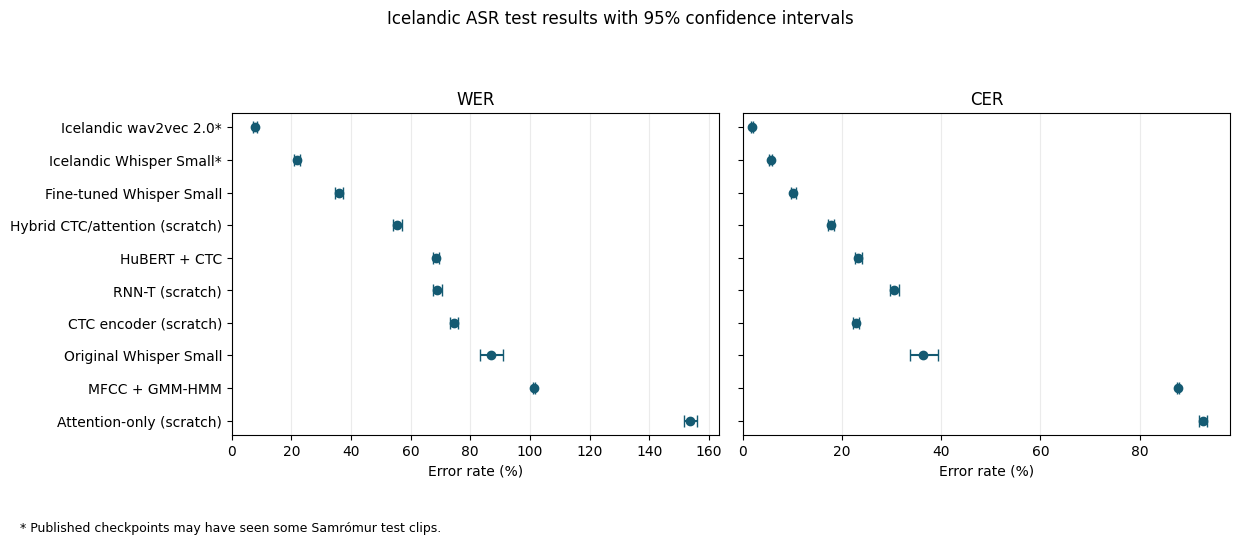

Saved /content/person4_ten_model_results/test_error_rates.png


In [9]:
import matplotlib.pyplot as plt

labels = {
    "hubert_ctc_test.csv": "HuBERT + CTC",
    "wav2vec2_is_test.csv": "Icelandic wav2vec 2.0*",
    "whisper_small_is_test_beam5.csv": "Icelandic Whisper Small*",
    "whisper_small_test_beam5.csv": "Original Whisper Small",
    "whisper_finetuned_step1000_test.csv": "Fine-tuned Whisper Small",
    "mfcc_gmm_hmm_test.csv": "MFCC + GMM-HMM",
    "rnnt_test.csv": "RNN-T (scratch)",
    "ctc_scratch_test.csv": "CTC encoder (scratch)",
    "attention_scratch_test.csv": "Attention-only (scratch)",
    "hybrid_ctc_attention_test.csv": "Hybrid CTC/attention (scratch)",
}

scores = pd.DataFrame(ci_rows)
model_order = (
    scores[scores["metric"] == "WER"]
    .sort_values("score_percent")["model_file"]
    .tolist()
)

fig, axes = plt.subplots(1, 2, figsize=(12.5, max(5.5, 0.53 * len(model_order))), sharey=True)
positions = list(range(len(model_order)))

for ax, metric in zip(axes, ("WER", "CER")):
    subset = scores[scores["metric"] == metric].set_index("model_file").loc[model_order]
    values = subset["score_percent"].to_numpy()
    errors = [
        values - subset["ci_low_percent"].to_numpy(),
        subset["ci_high_percent"].to_numpy() - values,
    ]

    ax.errorbar(values, positions, xerr=errors, fmt="o", capsize=4, color="#145A72")
    ax.set_title(metric)
    ax.set_xlabel("Error rate (%)")
    ax.set_xlim(left=0)
    ax.grid(axis="x", alpha=0.25)

axes[0].set_yticks(positions, labels=[labels.get(name, name) for name in model_order])
axes[0].invert_yaxis()
fig.suptitle("Icelandic ASR test results with 95% confidence intervals")
fig.text(0.02, 0.03, "* Published checkpoints may have seen some Samrómur test clips.", fontsize=9)
fig.tight_layout(rect=(0, 0.10, 1, 0.92))

chart_path = results_dir / "test_error_rates.png"
fig.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved {chart_path}")

## 8. Original Whisper's digit-versus-word errors (diagnostic only)

Muhammet flagged a mismatch between number words in references and numeric digits output by original Whisper. We identify all test hypotheses containing an ASCII or Unicode digit, show representative raw reference-versus-prediction examples, and export the examples. **No digit-to-word conversion is made:** the official frozen normalization and WER/CER scores above remain unchanged. Not every digit-containing transcript is exclusively a digit/word error; inspect the surrounding text.


In [10]:
import re

original_rows = rows_by_model["whisper_small_test_beam5.csv"]
digit_rows = [row for row in original_rows if re.search(r"\d", row["hypothesis_raw"])]
print(f"Original Whisper predictions containing digits: {len(digit_rows)} / {len(original_rows)}")
assert len(digit_rows) == 39, "Unexpected digit count; recheck the baseline CSV"

digit_examples = []
for row in digit_rows:
    digit_examples.append({
        "clip_id": row["id"],
        "reference_raw": row["reference_raw"],
        "prediction_raw": row["hypothesis_raw"],
        "reference_normalized": normalize_text(row["reference_raw"]),
        "prediction_normalized": normalize_text(row["hypothesis_raw"]),
    })

for item in digit_examples[:8]:
    print(f"\n{item['clip_id']}: {item['reference_raw']}\n    → {item['prediction_raw']}")

pd.DataFrame(digit_examples).to_csv(results_dir / "original_whisper_digit_examples.csv", index=False)
print(f"Saved {results_dir / 'original_whisper_digit_examples.csv'} ({len(digit_examples)} rows)")


Original Whisper predictions containing digits: 39 / 1884

0026095: Jovina, hvenær kemur leið fimmtíu og eitt?
    → Jo vinn að, fenni að kemuleið 5-1.

0020229: Einatóma anjónirnar koma úr flokki málmleysingja en mínushlaðnar sameindajónir eru einnig töluvert algengar.
    → Ein átum að anjónitnar komar flokki maðumlæsingja, en mínustlanar saman þegyónir eru eitt í 12. alkingar.

0007804: Árin nítján hundrað og tólf til nítján hundrað og fimmtán var hún aðstoðarmaður hans.
    → Ári 1912 til 1915 var hún ástvarmaðar hans.

0006330: Sjónvarpsþættirnir nutu mikilla vinsælda á Íslandi á áttunda áratugnum.
    → Sjórnors stættinnir, núðið þið míkið til að vinnsálja þá Íslandi á 8. árodigna.

0000138: Þessi tölva var framleidd í samvinnu Intel og Sandia National Laboratories í Bandaríkjunum.
    → Þessu 12. var frannleit í samvennu Íttel og Sandiða nátsynna labratoris í Pantaríganum.

0070372: Ég er tuttugu og fimm ára og finnst ég hafa nægan tíma.
    → Ég er 25 ára og finnst ég hafa næra

## 9. Deliverables and interpretation

After running, `person4_ten_model_results/` contains:

- `model_scores_and_confidence_intervals.csv` — **20 rows**, ten models × WER/CER.
- `paired_comparisons.csv` — **90 rows**, 45 model pairs × WER/CER.
- `error_counts.csv` — **10 rows** of substitution, deletion, insertion and exact word-boundary counts.
- `error_examples.csv` — representative errors (38 rows in the independently checked ten-model run).
- `whisper_finetuning_comparison.csv` — **2 rows**, calculated from the paired statistics.
- `methods.json`, `test_error_rates.png` and `original_whisper_digit_examples.csv` (39 flagged original-Whisper predictions).

**Strongest from-scratch model:** The hybrid CTC/attention model scored **55.57% WER / 17.77% CER**. Its WER was **12.89 percentage points lower than HuBERT + CTC** (95% paired CI for HuBERT minus hybrid: **11.63 to 14.15 pp**), with Holm-adjusted p≈**0.00900** across 90 comparisons. Note HuBERT uses a pretrained encoder, while the hybrid model was trained from scratch on the team's 15-hour train set.

**Whisper improvement:** The recovered fine-tuned Whisper achieved **50.76 pp lower WER** than original multilingual Whisper (95% CI **47.31–54.85 pp**) and **26.19 pp lower CER** (95% CI **23.48–29.17 pp**). Paired Monte Carlo p≈**0.00010**, Holm-adjusted p≈**0.00900**. Different decoding settings (original beam=5; fine-tuned greedy) limit causal interpretation.

**RNN-T versus HuBERT:** WER differs by **0.49 pp**, not statistically significant (HuBERT minus RNN-T 95% CI **−1.94 to +0.93 pp**; Holm-adjusted **p=0.55114**). HuBERT has lower CER (23.31% versus 30.54%; Holm-adjusted p≈0.00900).

**Attention-only failure:** The attention-only model has **153.82% WER / 92.79% CER**; the experiment failed to learn a useful alignment. WER may exceed 100% if combined substitutions, deletions and insertions exceed the number of reference words.

**Classical baseline:** MFCC + GMM-HMM scored **101.47% WER / 87.74% CER**. Its 16-training-clip memorization diagnostic was poor, and a train/dev-only realignment attempt worsened a small dev sample; the final frozen test model was left unchanged.

**Reproducibility and caveats:** The Whisper prediction input is verified with a fixed SHA-256. Published Icelandic checkpoints may overlap with the external training material. The digit-versus-word analysis remains a diagnostic and does **not change the frozen scoring normalization**.
